In [18]:
from astropy.io import fits
import numpy as np
import glob

# Find all matching files (adjust path if needed)
files = sorted(glob.glob("M1e5_r10_s10_peak5_d*.fits"))

# Read the first file to get shape and header
with fits.open(files[0]) as hdul:
    data_sum = hdul[0].data.astype(np.float64)
    header = hdul[0].header

# Add the rest
for f in files[1:]:
    with fits.open(f) as hdul:
        data_sum += hdul[0].data.astype(np.float64)

# Save the summed cube
fits.writeto("M1e5_r10_s10_peak5_37sources.fits", data_sum, header, overwrite=True)

print(f"Added {len(files)} files → saved as M1e5_r10_s10_sum.fits")


Added 37 files → saved as M1e5_r10_s10_sum.fits


In [6]:
import os
os.getcwd()

'/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/Fake_sources'

In [19]:
from astropy.table import Table, vstack
import glob

# Path to your FITS tables
path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/Fake_sources/M1e5_r10_s10_peak5*cat.FIT"

# Read all tables
tables = [Table.read(f) for f in glob.glob(path)]

# Concatenate them vertically
combined = vstack(tables)

# Save the result
combined.write("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/Fake_sources/M1e5_r10_s10_peak5_37sources_catalogue.FIT", overwrite=True)

print(f"Combined {len(tables)} tables into one with {len(combined)} rows.")


Combined 37 tables into one with 37 rows.


Gaussian fit to pixel histogram:
  Amplitude = 1311430.7744
  Mean      = 0.0237
  Sigma     = 0.3908


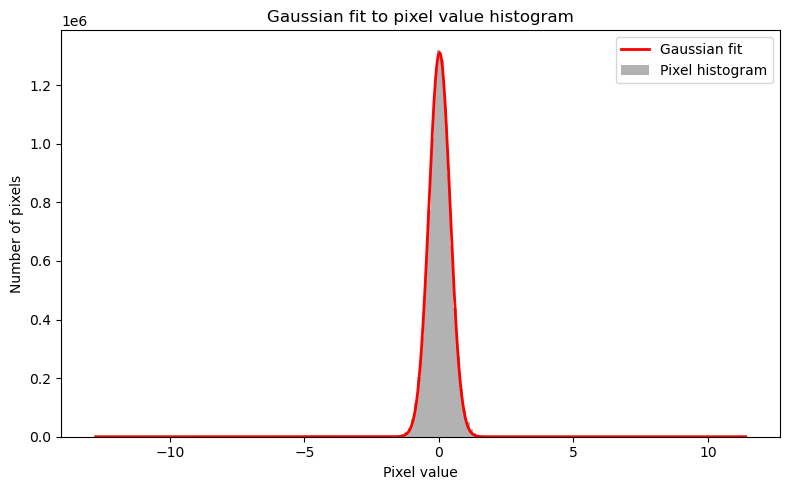

In [17]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
from astropy.io import fits
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Gaussian function
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma)**2)

# Load FITS data
fname = "/Users/kyriakos.trakakis/Downloads/FGN_027_13CO_23arcsec_noise.fits"
with fits.open(fname) as hdul:
    data = hdul[0].data.astype(float)

# Flatten and remove NaNs/Infs
y = data.ravel()
y = y[np.isfinite(y)]

# Make histogram
bins = 200
hist, bin_edges = np.histogram(y, bins=bins, range=(np.min(y), np.max(y)))
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

# Initial guesses for Gaussian
amp0 = hist.max()
mean0 = np.mean(y)
sigma0 = np.std(y)

# Fit Gaussian to histogram
popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[amp0, mean0, sigma0])
amp, mean, sigma = popt

# Print fit parameters
print(f"Gaussian fit to pixel histogram:")
print(f"  Amplitude = {amp:.4f}")
print(f"  Mean      = {mean:.4f}")
print(f"  Sigma     = {sigma:.4f}")

# Plot histogram and fit
x_fit = np.linspace(bin_centers.min(), bin_centers.max(), 1000)
y_fit = gaussian(x_fit, *popt)

plt.figure(figsize=(8,5))
plt.bar(bin_centers, hist, width=bin_edges[1]-bin_edges[0], alpha=0.6, color='gray', label='Pixel histogram')
plt.plot(x_fit, y_fit, 'r-', lw=2, label='Gaussian fit')
plt.xlabel('Pixel value')
plt.ylabel('Number of pixels')
plt.title('Gaussian fit to pixel value histogram')
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
from astropy.table import Table

# read catalog (should have only one row)
cat = Table.read("M1e5_r10_s10_peak5_d15_cat.FIT")

# confirm structure
print("Columns:", cat.colnames)
print("Number of rows:", len(cat))

# since it’s a single clump, extract directly
row = cat[0]

# get centroids
cen1 = float(row["Cen1"])
cen2 = float(row["Cen2"])
cen3 = float(row["Cen3"])

print(f"Centroids: Cen1={cen1:.3f}, Cen2={cen2:.3f}, Cen3={cen3:.3f}")


Columns: ['PIDENT', 'Peak1', 'Peak2', 'Peak3', 'Cen1', 'Cen2', 'Cen3', 'Size1', 'Size2', 'Size3', 'Sum', 'Peak', 'Volume', 'Shape']
Number of rows: 1
Centroids: Cen1=27.935, Cen2=0.210, Cen3=-10244.880


In [ ]:
def make_noise_cube(template_file, output_file, noise_sigma=0.44):
    """
    Create a cube with Gaussian random noise of given sigma.

    Parameters
    ----------
    template_file : str
        Path to template FITS cube (defines dimensions & header).
    output_file : str
        Path for output FITS file.
    noise_sigma : float
        RMS of Gaussian noise.
    """
    with fits.open(template_file) as hdul:
        header = hdul[0].header.copy()
        template_shape = hdul[0].data.shape

    # Gaussian noise
    noise_cube = np.random.normal(loc=0.0, scale=noise_sigma, size=template_shape).astype(np.float32)

    # Save FITS
    hdu = fits.PrimaryHDU(data=noise_cube, header=header)
    hdu.writeto(output_file, overwrite=True)

    print(f"Noise cube with σ={noise_sigma} saved to {output_file}")

template_file = ""
noise_file = "027_noise_file_rms044_2x2.fits"

make_noise_cube(template_file, noise_file, noise_sigma=noise_sigma)

Fitted A: 101.42942756338353


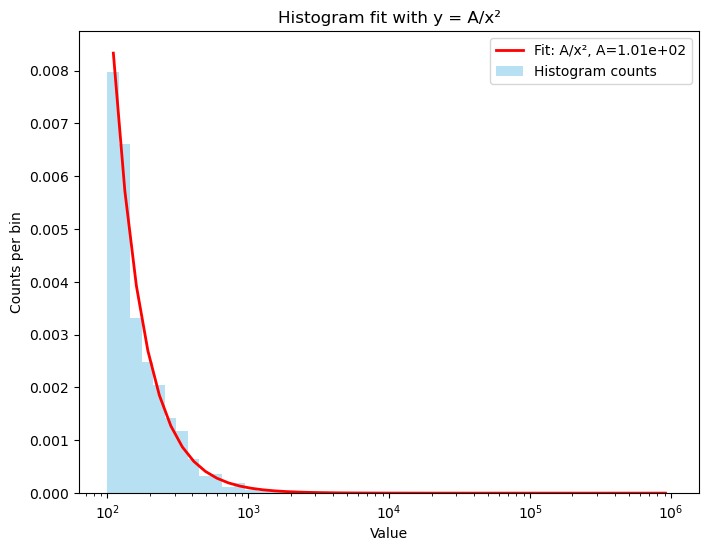

In [225]:
# Generate random masses scaled with the inverse of their mass squared
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def rand_inv_square(low=100, high=1_000_000, size=1):
    r = np.random.random(size)
    # inverse CDF of P(x) ∝ x^-2
    return low * high / (high - r * (high - low))

n_samples = 200
m_samples = rand_inv_square(size = n_samples)

# --- Make histogram ---
bins = np.logspace(np.log10(100), np.log10(1_000_000), 50)
hist_vals, bin_edges = np.histogram(m_samples, bins=bins, density=True)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# --- Fit function y = A / x^2 ---
def model(x, A):
    return A / x**2

popt, pcov = curve_fit(model, bin_centers, hist_vals)
A_fit = popt[0]
print("Fitted A:", A_fit)

# --- Plot ---
plt.figure(figsize=(8,6))
plt.bar(bin_centers, hist_vals, width=np.diff(bin_edges), alpha=0.6, color='skyblue', label='Histogram counts')
plt.plot(bin_centers, model(bin_centers, A_fit), 'r-', lw=2, label=f'Fit: A/x², A={A_fit:.2e}')
plt.xscale('log')
#plt.yscale('log')
plt.xlabel('Value')
plt.ylabel('Counts per bin')
plt.title('Histogram fit with y = A/x²')
plt.legend()
plt.show()


Fitted A: 0.00501238003373627


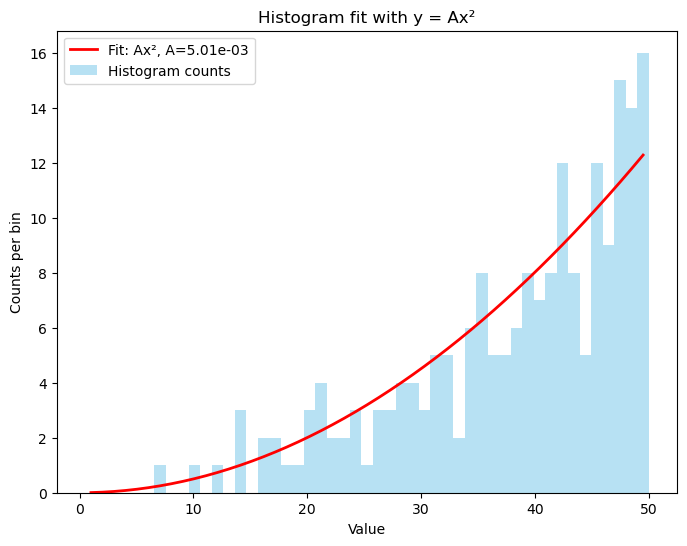

In [226]:
def rand_square_favored(a = 0.5, b = 50, size = 1):
    r = np.random.random(size)
    return (a**3 + r*(b**3 - a**3))**(1/3)

# Example
d_samples = rand_square_favored(size = n_samples)

# --- Make histogram ---
bins = np.linspace(0.5, 50, 50)
hist_vals, bin_edges = np.histogram(d_samples, bins=bins, density=False)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# --- Fit function y = A * x^2 ---
def model(x, A):
    return A * x**2

popt, pcov = curve_fit(model, bin_centers, hist_vals)
A_fit = popt[0]
print("Fitted A:", A_fit)

# --- Plot ---
plt.figure(figsize=(8,6))
plt.bar(bin_centers, hist_vals, width=np.diff(bin_edges), alpha=0.6, color='skyblue', label='Histogram counts')
plt.plot(bin_centers, model(bin_centers, A_fit), 'r-', lw=2, label=f'Fit: Ax², A={A_fit:.2e}')
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('Value')
plt.ylabel('Counts per bin')
plt.title('Histogram fit with y = Ax²')
plt.legend()
plt.show()

Fitted A: 0.168523935974217


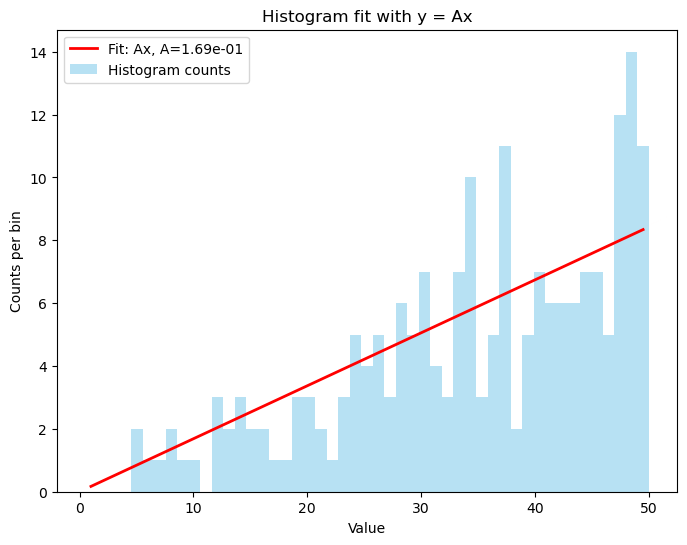

In [227]:
def rand_linear_favored(a=0.5, b=50.0, size=1):
    """
    Samples from PDF p(x) ∝ x on [a,b] (favors larger x).
    """
    r = np.random.random(size)
    return np.sqrt(a*a + r*(b*b - a*a))

# Example
d_samples = rand_linear_favored(size = n_samples)

# --- Make histogram ---
bins = np.linspace(0.5, 50, 50)
hist_vals, bin_edges = np.histogram(d_samples, bins=bins, density=False)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# --- Fit function y = A * x ---
def model(x, A):
    return A * x

popt, pcov = curve_fit(model, bin_centers, hist_vals)
A_fit = popt[0]
print("Fitted A:", A_fit)

# --- Plot ---
plt.figure(figsize=(8,6))
plt.bar(bin_centers, hist_vals, width=np.diff(bin_edges), alpha=0.6, color='skyblue', label='Histogram counts')
plt.plot(bin_centers, model(bin_centers, A_fit), 'r-', lw=2, label=f'Fit: Ax, A={A_fit:.2e}')
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('Value')
plt.ylabel('Counts per bin')
plt.title('Histogram fit with y = Ax')
plt.legend()
plt.show()

In [228]:
import pandas as pd

N = len(m_samples)
perm = np.random.permutation(N)
paired_m = m_samples
paired_d = d_samples[perm]

df_stars = pd.DataFrame({
    "Mass": paired_m,
    "Distance": paired_d
})
df_stars

,Mass,Distance
0,836.582626,33.370192
1,135.424738,49.849836
2,355.630219,27.469150
3,136.135039,49.615935
4,238.138264,24.958537
...,...,...
195,309.114835,37.218485
196,277.179073,17.095330
197,5686.915685,47.265114
198,307.694707,47.581979


In [233]:
paired_r = 10 ** ((np.log10(paired_m) - 2.76) / 2.11)
df_stars['Radius'] = paired_r

sv = 0.64 * paired_m ** (0.13)
df_stars['$\sigma_v$'] =sv

In [230]:
paired_m.max()

43380.91637468542

In [234]:
df_stars

,Mass,Distance,Radius,$\sigma_v$
0,836.582626,33.370192,1.194039,1.534992
1,135.424738,49.849836,0.503763,1.211437
2,355.630219,27.469150,0.796063,1.373440
3,136.135039,49.615935,0.505014,1.212261
4,238.138264,24.958537,0.658268,1.303670
...,...,...,...,...
195,309.114835,37.218485,0.744894,1.348639
196,277.179073,17.095330,0.707375,1.329655
197,5686.915685,47.265114,2.961458,1.969309
198,307.694707,47.581979,0.743271,1.347831


In [235]:
df_stars.to_csv('200_simulated_sources.csv')

Gaussian fit to pixel histogram:
  Amplitude = 58.8112
  Mean      = 4.0107
  Sigma     = 0.6913


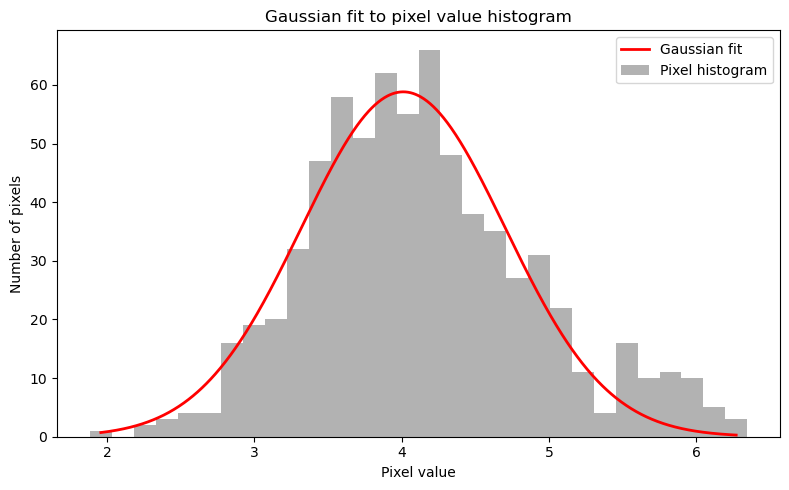

In [70]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
from astropy.io import fits
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Gaussian function
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma)**2)

# Load FITS data
data = np.array([
4.94491675, 4.493029819, 4.085219201, 3.579105339, 4.808022693,
6.115073532, 3.329719159, 5.524680365, 6.147617615, 4.796240784,
4.579467704, 4.246213389, 2.643669769, 3.648461497, 4.290635526,
4.648525207, 3.912175276, 4.93801509, 2.814407429, 4.053598517,
3.912347489, 3.469548103, 4.450088605, 5.21248554, 4.321680435,
4.097405174, 3.954303789, 3.825465066, 5.826864403, 3.241147862,
5.64032903, 4.926738483, 4.974760684, 5.743128218, 3.184589232,
3.246705338, 2.631910283, 3.03994526, 2.850658486, 3.675259444,
5.417247097, 3.6570482, 3.997440559, 3.462397998, 2.647969458,
3.721893016, 4.499437291, 3.722653663, 4.026234917, 3.246537971,
2.21779968, 4.089033176, 3.70304191, 3.246941512, 5.223054023,
4.585235063, 2.403995095, 4.322084643, 3.684903682, 2.736300867,
2.495877215, 4.033323213, 3.696358136, 3.648733636, 2.848817004,
2.893145659, 3.407888655, 3.208830864, 4.230397825, 3.575404938,
3.412053783, 4.21717193, 2.903713837, 3.76523628, 1.882638362,
3.385105563, 3.806139257, 4.093319404, 4.401821189, 3.187672979,
2.846930613, 3.074432425, 3.591876757, 3.443037565, 5.088656257,
4.480075245, 4.148029798, 4.040898888, 4.715232623, 3.979281525,
4.303983555, 3.496445292, 4.601456772, 3.026173587, 3.851113968,
3.56744751, 4.144927415, 4.510942529, 3.553280905, 3.834863039,
3.671535684, 5.068847267, 3.44878668, 5.104967847, 4.691106258,
3.489637911, 5.967073138, 3.694166296, 4.871563362, 5.949757479,
4.5810361, 5.11375329, 4.448251077, 5.511095906, 4.948897462,
3.389853321, 3.481241918, 4.247516649, 3.75005149, 5.253162507,
3.489576019, 3.97859817, 3.050341082, 4.715777285, 3.39557973,
3.39778711, 2.583788017, 3.785356889, 3.889343729, 2.775756038,
4.476018485, 3.509420287, 3.449077089, 4.720034209, 5.481611139,
2.469586403, 5.565002494, 3.505887652, 4.339534516, 4.032679993,
3.256919696, 3.283597443, 5.959414153, 4.428466546, 2.992146867,
3.915716338, 4.682480825, 4.815055418, 5.119894288, 3.476608485,
4.077626588, 3.53620354, 4.20172477, 5.128442567, 4.796734008,
4.998284802, 4.221909547, 4.51624244, 4.326895167, 4.034060254,
3.047107349, 5.56764607, 3.077247958, 2.791830948, 3.090582506,
3.593216264, 3.68507501, 3.188427843, 2.886716274, 4.594996054,
2.781611782, 3.490709763, 3.178999956, 3.955206538, 3.000746345,
3.335209088, 5.573796257, 4.048354781, 3.586857248, 5.096098793,
4.522598492, 3.652563483, 4.317833808, 3.720414015, 5.83853553,
2.978755542, 6.178802711, 4.064419051, 3.852089441, 3.271804446,
4.08842316, 3.95875686, 5.810608067, 3.901679499, 4.459869648,
2.602059991, 4.149599339, 4.495493968, 3.455993838, 4.490338637,
4.252086638, 3.35653829, 4.708092718, 4.816356655, 5.058614545,
4.180045549, 4.202675999, 3.704007159, 4.135020007, 3.954676587,
2.919224577, 3.434498645, 4.457132812, 2.912758613, 4.004477864,
3.391751731, 4.300633738, 5.259323328, 3.661002003, 2.826327527,
3.88631923, 4.244673373, 3.820710357, 2.989120412, 2.920598076,
3.083903763, 3.842074779, 3.095354192, 2.362821635, 3.273417995,
4.891000251, 4.123357636, 3.356366272, 3.077898184, 3.045135135,
3.640413853, 3.276978514, 3.042425866, 4.073434225, 4.135431623,
3.848134904, 3.522702386, 4.630635615, 5.880579993, 4.030417547,
4.085311275, 2.799795286, 3.504593182, 4.125077689, 3.793740808,
2.272305844, 3.482301767, 4.170566788, 5.31996505, 4.28404929,
2.527152817, 4.623975402, 3.786372314, 4.46435912, 4.954674659,
4.123869927, 3.324903608, 4.279258004, 4.173650045, 3.117403884,
4.165308441, 4.083655957, 4.257769743, 3.831880647, 4.245054443,
4.656381887, 3.521391784, 3.660222094, 2.936438338, 3.408604552,
2.968482949, 4.394984066, 2.977741891, 3.336127381, 3.637889817,
5.130068865, 4.35947576, 4.459372582, 4.329279068, 5.005904562,
5.737810738, 6.110276602, 6.345833351, 3.413293057, 3.859480552,
4.265077378, 5.618317443, 4.076217957, 3.841043334, 5.851500263,
4.787687906, 3.641799214, 4.847054652, 3.865359262, 4.700509712,
3.35328134, 5.656724783, 3.863695123, 4.421924594, 5.402000418,
3.967117212, 5.077359474, 6.233180101, 4.072480406, 4.494869339,
4.213353039, 5.981694134, 4.377983215, 4.060484417, 3.952453881,
5.034787829, 4.984223201, 4.224693595, 4.180001937, 4.589924592,
4.910878292, 4.936258218, 3.685379825, 3.969675852, 4.635216755,
4.037138334, 5.631870355, 4.485677995, 4.231535341, 4.796912202,
4.118793628, 4.196290618, 4.142294023, 3.66570854, 3.978892341,
4.148028563, 4.002813779, 3.820984586, 4.249086283, 4.059536155,
4.407394304, 3.692295994, 4.290468689, 5.031212644, 4.670568577,
5.527891584, 4.734764157, 4.166763034, 3.674536906, 5.043709103,
4.499621109, 4.046613769, 3.932422519, 3.855846722, 3.661282504,
3.592032339, 3.665903544, 4.868784577, 4.899139538, 3.668217199,
2.971067003, 3.690048927, 3.563243701, 4.687603864, 4.458864378,
3.979845997, 3.583968029, 4.07461204, 4.645308277, 3.481740656,
4.350792871, 4.660229691, 5.821014845, 4.871713825, 4.66144996,
3.877068271, 4.698236122, 4.927789465, 4.495454694, 4.099675117,
4.758804894, 4.14823236, 3.327518317, 5.272524769, 6.243357616,
5.518751789, 5.160142343, 3.951139272, 4.573577975, 4.354263681,
4.861431291, 5.485642991, 4.351665883, 5.587995912, 5.031863124,
5.558146744, 4.606635847, 3.919245499, 5.203231757, 3.737974623,
4.105143179, 5.010445065, 4.89625718, 3.705119303, 3.268896088,
4.195225835, 3.934388349, 3.937952971, 3.280193526, 3.630251884,
3.891348981, 4.73490739, 4.154700531, 3.4647339, 3.914643515,
4.208930737, 4.952630848, 4.276675911, 4.093424487, 4.992861435,
3.530938267, 4.305524623, 4.104290405, 3.643409245, 3.658364416,
4.683698712, 3.632076485, 3.26073902, 4.27829575, 4.261198374,
3.57567269, 4.206922975, 3.648008529, 3.825024746, 3.978122059,
3.597445066, 4.332276832, 3.680273856, 4.223644661, 3.797219052,
4.209315515, 4.788982864, 4.066286036, 4.409560518, 5.845392838,
5.982549093, 4.784171216, 5.045404352, 4.55643277, 4.260299214,
5.262370584, 3.935329884, 4.568129414, 5.912545132, 4.34462999,
4.409454291, 3.672054426, 4.010010613, 4.374853883, 3.697506575,
3.572834442, 5.526807094, 3.684029846, 4.594507905, 5.036762197,
3.764967755, 4.855353402, 4.400635544, 3.569912054, 4.490301844,
4.69311182, 3.621809599, 3.383348518, 4.528783051, 5.573407416,
3.749552358, 4.477694435, 5.796403877, 5.609378382, 3.610617583,
4.497369805, 3.28365621, 4.999456792, 4.490643113, 4.504558936,
4.616465011, 3.677721898, 3.859522565, 4.718234221, 3.630783708,
4.516893767, 4.474238415, 3.513526559, 5.815575158, 3.570991013,
4.409404213, 4.085564914, 3.854013174, 5.028796637, 3.784922404,
3.913489069, 4.172740378, 3.466794985, 3.567449862, 3.870741494,
4.859049387, 4.179220774, 4.131959808, 4.267605571, 4.906126196,
4.828519018, 3.497602698, 3.833705405, 4.313994539, 4.209592216,
3.163161375, 4.402126859, 4.045954789, 4.221442929, 4.262793644,
3.337938219, 4.334516478, 4.257790853, 3.59969098, 3.896759836,
3.581095924, 3.378666753, 4.406593996, 3.955410637, 3.55317399,
3.787913661, 3.885129874, 4.099827337, 3.469462654, 4.276367122,
3.828613501, 3.843253963, 3.53989371, 4.515042195, 4.202772395,
3.687002495, 4.328076103, 3.644383437, 3.595771702, 3.614475366,
4.755101581, 3.245275715, 4.624829725, 3.987092188, 4.318471964,
4.242058168, 3.785578949, 5.708194371, 3.962357495, 6.036704946,
3.877518774, 4.15685069, 4.219965742, 5.077520372, 4.818727353,
3.734962959, 4.54067352, 3.131798247, 3.690970914, 3.756961517,
4.043550104, 3.429463192, 3.523379632, 4.997965872, 2.954956096,
3.705519902, 3.927174732, 5.908584557, 4.149212952, 3.78446751,
4.0443704, 3.713021554, 4.376308086, 3.624806852, 3.304490528,
4.225837352, 5.029367096, 3.849150277, 6.070545004, 4.364307422,
4.045826234, 5.676857148, 3.491208963, 3.804679067, 3.261405627,
5.889474971, 3.311594944, 3.890072102, 4.02688448, 3.045009861,
3.261824114, 4.204661427, 4.40913613, 4.222533353, 4.817162221,
3.877928544, 4.924590419, 5.938351704, 5.942843556, 5.267997347,
4.874100585, 4.766999938, 4.143626131, 2.964325642, 4.796773397,
4.489930509, 3.725168124, 3.704776617, 4.589419193, 4.095209116,
5.724681066, 5.795542735, 5.155062619, 3.637187419, 4.266643211,
4.395554927, 3.291728393, 4.324515389, 3.194952578, 3.821231112,
3.529124803, 3.211857095, 3.686135559, 2.859834532, 3.096144981,
3.589164035, 4.583296508, 4.738775407, 3.912297002, 4.181513742,
3.442244528, 4.303829967, 3.881923054, 4.23061239, 4.213552552,
3.450101238, 3.263979109, 3.626142169, 3.403271554, 3.116162597,
3.891106852, 4.048872, 4.122451808, 3.574970643, 3.48507376,
3.765495696, 3.747528329, 3.898781658, 5.470014241, 3.046050106,
4.093001197, 4.061398943, 4.369027437, 4.247796077, 4.213626118,
5.471349691, 4.609563997, 4.675594323, 4.472611368, 4.656540708,
3.957435834, 4.89351143, 3.583923882, 3.489747606, 5.131289676,
5.002749569, 4.771193424, 3.799532837, 4.999067003, 3.616483916,
3.725895305, 5.45323808, 4.708153187, 4.329994294, 3.466482068,
4.837081887, 4.880696946, 5.167094103, 3.496376054, 3.811755924,
5.215735725, 4.077306845, 4.22371031, 3.858428911, 2.926188049,
3.852303678, 3.936674563, 4.027942535, 3.340903946, 3.081390519,
3.261938177, 3.473387691, 4.436357956, 3.499879449, 5.429996772,
3.856857529, 3.402708347, 4.22572838, 3.643768412, 4.451141421,
3.928113059, 3.16559447, 3.32133533, 3.407117153, 4.544764095,
3.646556634
])

# Flatten and remove NaNs/Infs
y = data.ravel()
y = y[np.isfinite(y)]

# Make histogram
bins = 30
hist, bin_edges = np.histogram(y, bins=bins, range=(np.min(y), np.max(y)))
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

# Initial guesses for Gaussian
amp0 = hist.max()
mean0 = np.mean(y)
sigma0 = np.std(y)

# Fit Gaussian to histogram
popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[amp0, mean0, sigma0])
amp, mean, sigma = popt

# Print fit parameters
print(f"Gaussian fit to pixel histogram:")
print(f"  Amplitude = {amp:.4f}")
print(f"  Mean      = {mean:.4f}")
print(f"  Sigma     = {sigma:.4f}")

# Plot histogram and fit
x_fit = np.linspace(bin_centers.min(), bin_centers.max(), 1000)
y_fit = gaussian(x_fit, *popt)

plt.figure(figsize=(8,5))
plt.bar(bin_centers, hist, width=bin_edges[1]-bin_edges[0], alpha=0.6, color='gray', label='Pixel histogram')
plt.plot(x_fit, y_fit, 'r-', lw=2, label='Gaussian fit')
plt.xlabel('Pixel value')
plt.ylabel('Number of pixels')
plt.title('Gaussian fit to pixel value histogram')
plt.legend()
plt.tight_layout()
plt.show()

In [249]:
matched.write("200_clumps_matched.csv", format="csv", overwrite=True)

In [16]:
import numpy as np
from astropy.table import Table, hstack, vstack
from scipy.spatial import cKDTree
import os

def match_catalogues_full_fluxfiltered(
        t1, t2,
        l1_col="x_cen", b1_col="y_cen", v1_col="v_cen",
        l2_col="Cen1", b2_col="Cen2", v2_col="Cen3",
        id1_col="_idx", id2_col="PIDENT",
        flux1_col="flux",
        l_tol=0.07, b_tol=0.07, v_tol=2000.0):
    """
    Match two FITS tables on (l,b,v), combine full columns,
    and if multiple t1 entries map to the same t2 entry,
    keep only the t1 entry with the highest flux.
    """

    # Extract columns
    l1, b1, v1 = t1[l1_col], t1[b1_col], t1[v1_col]
    l2, b2, v2 = t2[l2_col], t2[b2_col], t2[v2_col]

    # Build KD-tree in scaled coordinate space
    coords1 = np.vstack([l1/l_tol, b1/b_tol, v1/v_tol]).T
    coords2 = np.vstack([l2/l_tol, b2/b_tol, v2/v_tol]).T

    tree = cKDTree(coords2)
    dist, idx = tree.query(coords1, k=1)

    # Scaled distance filter
    scaled_dist = np.sqrt(
        ((l1 - l2[idx]) / l_tol) ** 2 +
        ((b1 - b2[idx]) / b_tol) ** 2
    )

    v_dist = np.sqrt(((v1 - v2[idx]) / v_tol) ** 2)
    
    good = (scaled_dist < 1.0) & (v_dist < 1.0)

    # Extract matched subsets
    t1_match = t1[good]
    t2_match = t2[idx[good]]

    # Add temporary index column to allow grouping
    t1_ids = t1_match[id1_col]
    t2_ids = t2_match[id2_col]

    merged = Table()
    merged["t1_id"] = t1_ids
    merged["t2_id"] = t2_ids
    merged["flux"] = t1_match[flux1_col]

    # Build full merged rows
    t1_prefixed = t1_match.copy()
    t2_prefixed = t2_match.copy()
    t1_prefixed.rename_columns(t1_prefixed.colnames,
                               [f"{c}" for c in t1_prefixed.colnames])
    t2_prefixed.rename_columns(t2_prefixed.colnames,
                               [f"{c}" for c in t2_prefixed.colnames])

    full = hstack([t1_prefixed, t2_prefixed])

    # ---- FILTER: keep only highest-flux match per t2_id ----
    unique_t2 = {}
    for row in full:
        t2_id = row[id2_col]
        flux_val = row[flux1_col]

        if t2_id not in unique_t2:
            unique_t2[t2_id] = row
        else:
            if flux_val > unique_t2[t2_id][flux1_col]:
                unique_t2[t2_id] = row

    filtered = vstack(list(unique_t2.values()))

    return filtered

os.chdir('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO')

t1 = Table.read("FGN_027_injection_200b_clusters_leaves_catalogue.fits")
t2 = Table.read("FGN_027_injection_200b.FIT")

matched = match_catalogues_full_fluxfiltered(t1, t2)

matched.write("FGN_027_injection_200b_matches_flux_filtered.csv", format="csv", overwrite=True)

print(len(matched), "matches retained after flux filtering")

os.chdir('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/Fake_Sources')

194 matches retained after flux filtering


In [3]:
matched

_idx,area_exact,flux,v_cen,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type,PIDENT,Peak1,Peak2,Peak3,Cen1,Cen2,Cen3,Size1,Size2,Size3,Sum,Peak,Volume,Shape
,pix2,Jy,,,,,,,,,,,,deg,deg,m / s,deg,deg,m / s,arcsec,arcsec,m / s,,,arcsec2 m / s,
int64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bytes83
22,209.0,938.9487048983574,140293.35907074914,26.793035439858436,0.5219705157073835,0.7393073347563087,22.05435333472887,20.581669209897996,-1,22,2,T,251,2.6793147566e+01,5.2171829050e-01,1.4025521623e+05,2.6793147566e+01,5.2171829050e-01,1.4025521623e+05,3.0751784083e+01,2.9485630186e+01,9.1228027809e+02,2.2744003988e+03,1.9232508006e+00,1.0033559516e+08,Ellipse GALACTIC TOPOCENTER 26.79273 0.5221349 0.008552166 0.008180019 279.5664
35,166.0,461.54830199480057,140273.1733542528,27.318350948983838,-0.8436360774245898,0.5017403390036175,24.245587064814814,17.54629060402209,-1,35,2,T,23,2.7318143398e+01,-8.4319001513e-01,1.4025521623e+05,2.7318143398e+01,-8.4319001513e-01,1.4025521623e+05,2.6722744750e+01,3.2603776724e+01,6.0453432000e+02,1.3580496877e+03,1.7545534087e+00,6.4398134533e+07,Ellipse GALACTIC TOPOCENTER 27.31773 -0.8427735 0.009060994 0.007417613 356.8816
77,163.0,392.60481345653534,140248.8540404103,27.317884532270963,0.20687018548336694,0.4358257154942479,22.650703597435598,19.64237353970952,-1,77,2,T,193,2.7318143397e+01,2.0673202686e-01,1.4025521623e+05,2.7318143397e+01,2.0673202686e-01,1.4025521623e+05,3.5056169083e+01,2.6442014081e+01,4.2759630850e+02,1.0583416592e+03,1.8893697713e+00,4.9442750549e+07,Ellipse GALACTIC TOPOCENTER 27.31773 0.2071487 0.01008258 0.006864177 290.7283
103,167.0,539.6911348104477,140239.4920661901,27.948406771568923,0.6264759498318376,0.5102423996446356,20.076669534856208,19.24988383667276,-1,103,2,T,258,2.7948060130e+01,6.2662532819e-01,1.4025521623e+05,2.7948060130e+01,6.2662532819e-01,1.4025521623e+05,2.7340764029e+01,2.7363888920e+01,5.2682477111e+02,1.2376981642e+03,2.2330208286e+00,5.2007307235e+07,Ellipse GALACTIC TOPOCENTER 27.94764 0.6270419 0.007601044 0.007594684 183.0722
105,272.0,784.4379976987839,140254.38517600528,26.79306458805751,0.6270105481959427,0.47154105226428417,28.634982485640183,24.20676207254292,-1,105,2,T,268,2.6793147566e+01,6.2670703084e-01,1.4025521623e+05,2.6793147566e+01,6.2670703084e-01,1.4025521623e+05,3.8775467963e+01,4.1131242616e+01,4.9332985628e+02,2.1131266153e+03,1.8604458072e+00,9.7918551601e+07,Ellipse GALACTIC TOPOCENTER 26.79273 0.6271236 0.01203872 0.01008093 215.1915
327,110.0,215.29335498809814,140235.0726468177,26.688747630851527,0.5228430795056993,0.27589084556897925,20.081395343098198,16.903215285440506,-1,327,2,T,252,2.6688149747e+01,5.2171396300e-01,1.4025521623e+05,2.6688149747e+01,5.2171396300e-01,1.4025521623e+05,2.5607174239e+01,2.5273083968e+01,2.6299259603e+02,5.4544974620e+02,2.1848045008e+00,2.4817820646e+07,Ellipse GALACTIC TOPOCENTER 26.68773 0.5221305 0.007113906 0.007019504 264.7849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5652,83.0,168.38125562667847,-39782.12895515295,26.68892898356317,0.7311852775387863,0.30903525475420274,16.627956911982317,13.793261651987207,-1,5652,1,L,5209,2.6688149747e+01,7.3168549371e-01,-3.9744784329e+04,2.6688149747e+01,7.3168549371e-01,-3.9744784329e+04,2.5703221477e+01,2.1956496688e+01,2.6919761500e+02,4.8937236396e+02,2.2279961384e+00,2.2223586645e+07,Ellipse GALACTIC TOPOCENTER 26.68773 0.732102 0.007396482 0.005784954 294.7877


In [19]:
from astropy.io import fits
import numpy as np

# Paths
small_cube_path = "027_noise_file_rms044.fits"
big_cube_path = "6000_clumps_noisy.fits"
output_path = "new_cube.fits"

# Load headers and data shapes
header_small = fits.getheader(small_cube_path)
header_big = fits.getheader(big_cube_path)
data_small = fits.getdata(small_cube_path)

# Original small cube info
n_vel = header_small['NAXIS3']
n_lon = header_small['NAXIS1']
n_lat_small = header_small['NAXIS2']
lat_min_small = header_small['CRVAL2'] - (header_small['CRPIX2']-1)*header_small['CDELT2']
lat_max_small = lat_min_small + n_lat_small*header_small['CDELT2']

# Large cube latitude range
n_lat_big = header_big['NAXIS2']
lat_min_big = header_big['CRVAL2'] - (header_big['CRPIX2']-1)*header_big['CDELT2']
lat_max_big = lat_min_big + n_lat_big*header_big['CDELT2']

# New latitude axis: double the small cube
n_lat_new = int((lat_max_big - lat_min_big) / abs(header_small['CDELT2']))

# Create empty data array
data_new = np.zeros((n_vel, n_lat_new, n_lon), dtype=data_small.dtype)

# Start with small cube header
new_header = header_small.copy()
new_header['NAXIS2'] = n_lat_new

# Adjust reference pixel to keep CRVAL2 at the same value for the center of the new latitude
# New CRPIX2 corresponds to same CRVAL2
old_crval = header_small['CRVAL2']
old_crpix = header_small['CRPIX2']
cdelt = header_small['CDELT2']

new_crpix = (old_crval - lat_min_big)/cdelt + 1
new_header['CRPIX2'] = new_crpix

# Write new FITS
fits.writeto(output_path, data_new, new_header, overwrite=True)

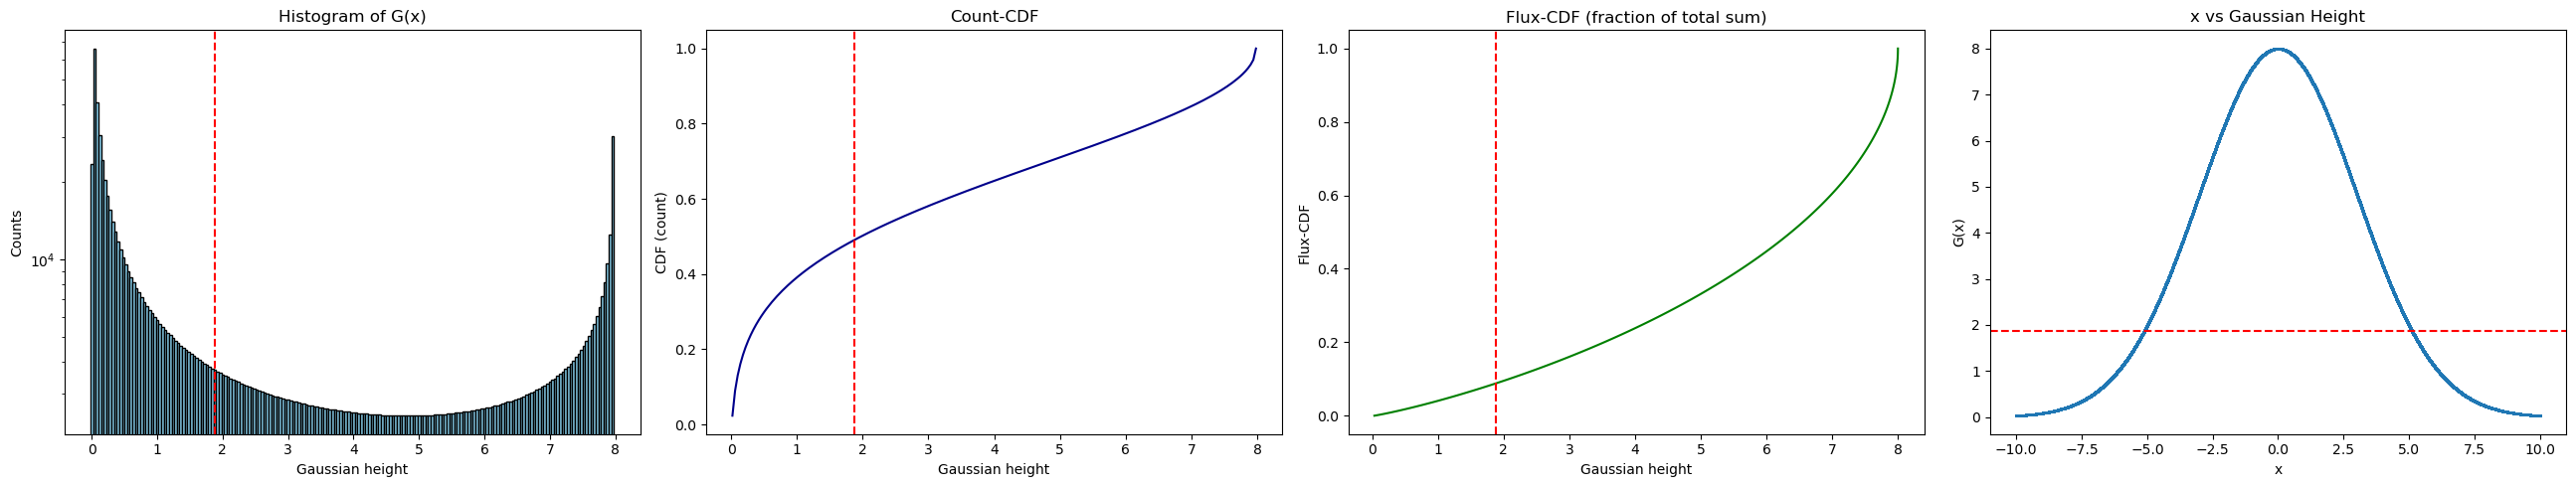

Percentage of sum below threshold: 8.799869880737724 %
Percentage of points with height < threshold: 48.9442 %


In [147]:
import numpy as np
import matplotlib.pyplot as plt

def gaussian_analysis_with_x(peak, sigma, height_thresh, n_points=1_000_000, bins=200):
    """
    peak:          A, peak value of the Gaussian
    sigma:         sigma of the Gaussian
    height_thresh: threshold applied to Gaussian height G(x)
    n_points:      number of x samples (not random in this version)
    bins:          number of bins for histogram
    """
    mu = 0.0
    
    # Use evenly spaced x instead of random sampling
    x = np.linspace(-10, 10, n_points)
    
    # Gaussian height
    G = peak * np.exp(-0.5 * ((x - mu) / sigma)**2)
    
    # Mask for values below threshold
    mask = G < height_thresh
    
    # Stats
    count_below = np.count_nonzero(mask)
    total_count = n_points
    sum_below = G[mask].sum()
    total_sum = G.sum()
    fraction = sum_below / total_sum
    
    # Histogram
    hist, bin_edges = np.histogram(G, bins=bins, range=(0, peak))
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    
    # Count-CDF
    cdf = np.cumsum(hist) / hist.sum()
    
    # -------------------------
    # FLUX-CDF (the "real" one)
    # -------------------------
    G_sorted = np.sort(G)
    cum_flux = np.cumsum(G_sorted)
    flux_cdf = cum_flux / cum_flux[-1]     # normalized cumulative flux
    # -------------------------
    
    # Plotting
    fig, ax = plt.subplots(1, 4, figsize=(26,5))
    
    # 1. Histogram
    ax[0].bar(bin_edges[:-1], hist, 
              width=(bin_edges[1]-bin_edges[0]), 
              color='skyblue', edgecolor='k')
    ax[0].axvline(height_thresh, color='r', linestyle='--')
    ax[0].set_xlabel('Gaussian height')
    ax[0].set_ylabel('Counts')
    ax[0].set_title('Histogram of G(x)')
    ax[0].set_yscale('log')
    
    # 2. Count-CDF
    ax[1].plot(bin_centers, cdf, color='darkblue')
    ax[1].axvline(height_thresh, color='r', linestyle='--')
    ax[1].set_xlabel('Gaussian height')
    ax[1].set_ylabel('CDF (count)')
    ax[1].set_title('Count-CDF')

    # 3. Flux-CDF
    ax[2].plot(G_sorted, flux_cdf, color='green')
    ax[2].axvline(height_thresh, color='r', linestyle='--')
    ax[2].set_xlabel('Gaussian height')
    ax[2].set_ylabel('Flux-CDF')
    ax[2].set_title('Flux-CDF (fraction of total sum)')
    
    # 4. x vs G(x)
    ax[3].scatter(x, G, s=1, alpha=0.3)
    ax[3].axhline(height_thresh, color='r', linestyle='--')
    ax[3].set_xlabel('x')
    ax[3].set_ylabel('G(x)')
    ax[3].set_title('x vs Gaussian Height')
    
    
    plt.tight_layout()
    plt.show()
    
    return fraction, sum_below, total_sum, count_below, total_count


# Example usage
peak = 8
sigma = 3
height_thresh = 1.88

fraction, below_sum, total_sum, count_below, total_count = gaussian_analysis_with_x(
    peak, sigma, height_thresh
)

print("Percentage of sum below threshold:", below_sum / total_sum * 100, "%")
print("Percentage of points with height < threshold:", count_below / total_count * 100, "%")


Percentage of pixels below threshold: 89.38%
Percentage of total flux below threshold: 4.14%
Total number of pixels: 55083.000000
Total flux: 13778.972656


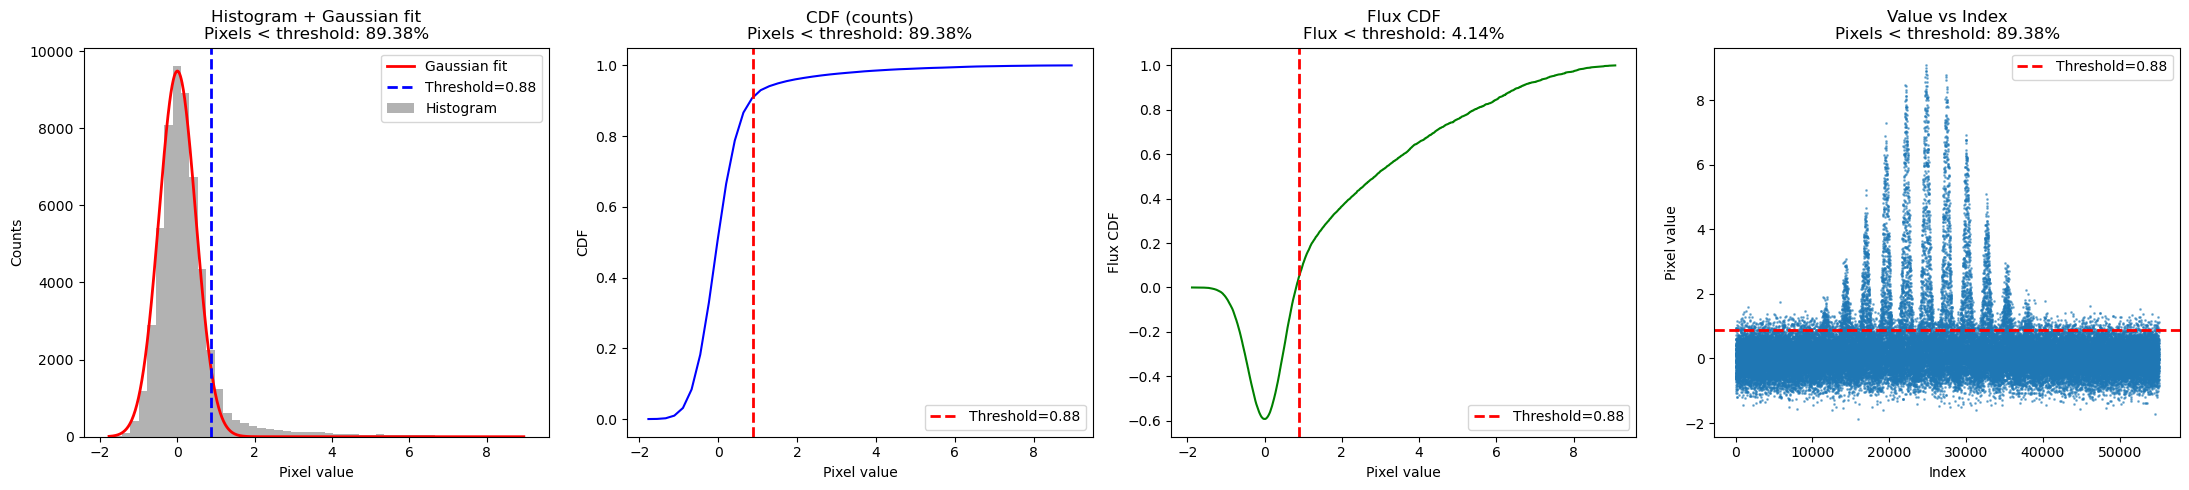

In [270]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# -----------------------
# Load and flatten FITS data
# -----------------------
data = fits.getdata('6000clumps_noisy_example.fits')
y = data.ravel()
y = y[np.isfinite(y)]
#y = y[y>0]

# -----------------------
# Threshold
# -----------------------
value_thresh = 0.88  # <-- set your desired threshold here

# Mask for pixels below threshold
mask = y < value_thresh

# Counts below threshold
count_below = np.count_nonzero(mask)
total_count = y.size
count_fraction = count_below / total_count * 100

# Flux below threshold
sum_below = y[mask].sum()
total_sum = y.sum()
flux_fraction = sum_below / total_sum * 100

print(f"Percentage of pixels below threshold: {count_fraction:.2f}%")
print(f"Percentage of total flux below threshold: {flux_fraction:.2f}%")
print(f"Total number of pixels: {total_count:2f}")
print(f"Total flux: {total_sum:2f}")

# -----------------------
# Histogram + Gaussian fit
# -----------------------
bins = 50
hist, bin_edges = np.histogram(y, bins=bins, range=(y.min(), y.max()))
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

# Gaussian-like function
def gaussian_drop(x, amp, sigma):
    return amp * np.exp(-0.5 * (x / sigma)**2)

# Fit initial guesses
amp0 = hist.max()
sigma0 = np.std(y)

popt, _ = curve_fit(gaussian_drop, bin_centers, hist, p0=[amp0, sigma0])
amp, sigma = popt

x_fit = np.linspace(bin_centers.min(), bin_centers.max(), 1000)
y_fit = gaussian_drop(x_fit, *popt)

# -----------------------
# CDF (cumulative counts)
# -----------------------
cdf_counts = np.cumsum(hist) / np.sum(hist)

# -----------------------
# Flux-CDF (cumulative sum of values)
# -----------------------
y_sorted = np.sort(y)
cum_flux = np.cumsum(y_sorted)
flux_cdf = cum_flux / cum_flux[-1]

# -----------------------
# Value vs Index scatter
# -----------------------
indices = np.arange(y.size)

# -----------------------
# PLOT EVERYTHING
# -----------------------
fig, ax = plt.subplots(1, 4, figsize=(22,5))

# --- Plot 1: Histogram + Gaussian fit ---
ax[0].bar(bin_centers, hist, width=bin_edges[1]-bin_edges[0],
          alpha=0.6, color='gray', label='Histogram')
ax[0].plot(x_fit, y_fit, 'r-', lw=2, label='Gaussian fit')
ax[0].axvline(value_thresh, color='blue', linestyle='--', lw=2, label=f'Threshold={value_thresh}')
ax[0].set_title(f"Histogram + Gaussian fit\nPixels < threshold: {count_fraction:.2f}%")
ax[0].set_xlabel("Pixel value")
ax[0].set_ylabel("Counts")
ax[0].legend()
#ax[0].set_yscale('log')

# --- Plot 2: CDF of counts ---
ax[1].plot(bin_centers, cdf_counts, color='blue')
ax[1].axvline(value_thresh, color='red', linestyle='--', lw=2, label=f'Threshold={value_thresh}')
ax[1].set_title(f"CDF (counts)\nPixels < threshold: {count_fraction:.2f}%")
ax[1].set_xlabel("Pixel value")
ax[1].set_ylabel("CDF")
ax[1].legend()

# --- Plot 3: Flux CDF (cumulative SUM) ---
ax[2].plot(y_sorted, flux_cdf, color='green')
ax[2].axvline(value_thresh, color='red', linestyle='--', lw=2, label=f'Threshold={value_thresh}')
ax[2].set_title(f"Flux CDF\nFlux < threshold: {flux_fraction:.2f}%")
ax[2].set_xlabel("Pixel value")
ax[2].set_ylabel("Flux CDF")
ax[2].legend()

# --- Plot 4: Values vs Index ---
ax[3].scatter(indices, y, s=1, alpha=0.5)
ax[3].axhline(value_thresh, color='red', linestyle='--', lw=2, label=f'Threshold={value_thresh}')
ax[3].set_title(f"Value vs Index\nPixels < threshold: {count_fraction:.2f}%")
ax[3].set_xlabel("Index")
ax[3].set_ylabel("Pixel value")
ax[3].legend()

plt.tight_layout()
plt.show()


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_25215/3387629704.py:91: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


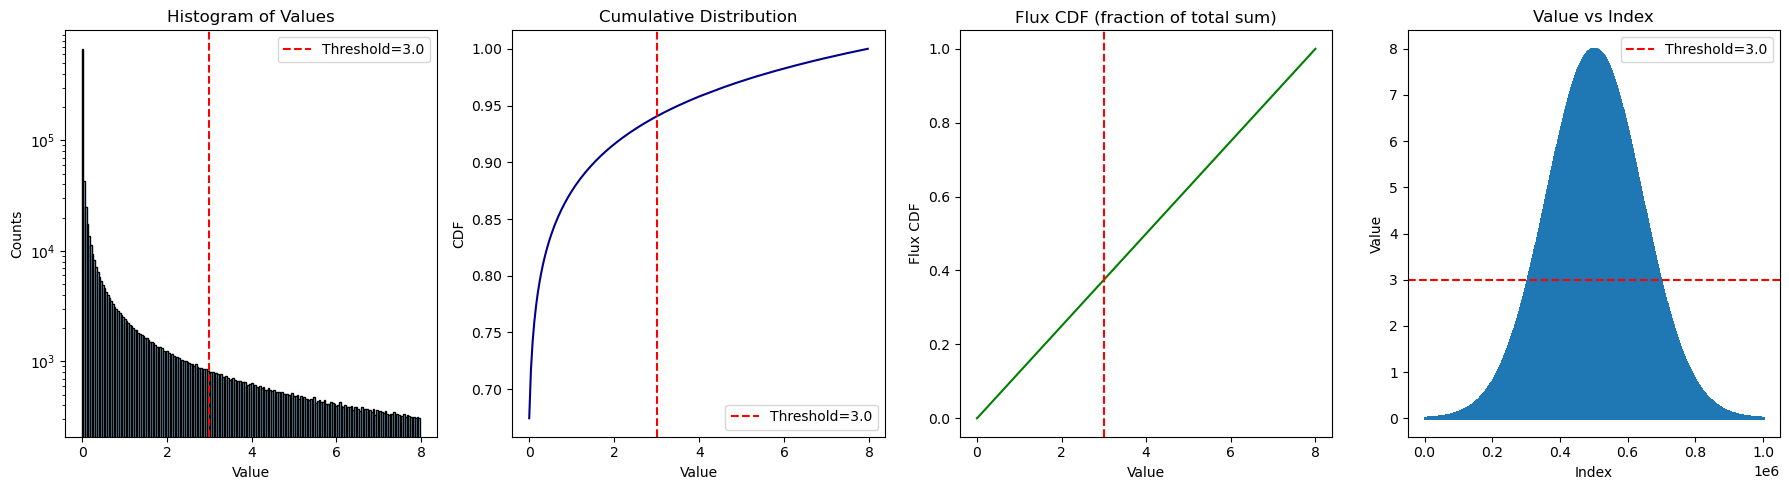

Fraction of total sum below threshold: 37.467331435313646 %
Percentage of points below threshold: 93.9726 %
Total number of points: 1000000


In [201]:
import numpy as np
import matplotlib.pyplot as plt

def analyze_values(data, value_thresh, bins=200, show_plots=True):
    """
    Analyze an array of values (e.g., pixel intensities in a clump).

    Parameters:
    ----------
    data : array-like
        Input values (1D, 2D, or 3D).
    value_thresh : float
        Threshold applied to the data values.
    bins : int
        Number of bins for histogram.
    show_plots : bool
        If True, plot histogram, cumulative, and values vs index.

    Returns:
    -------
    fraction : float
        Fraction of total sum below threshold.
    sum_below : float
        Sum of values below threshold.
    total_sum : float
        Total sum of all values.
    count_below : int
        Number of values below threshold.
    total_count : int
        Total number of values.
    """
    
    # Flatten the array
    data_flat = np.ravel(data)
    
    # Mask for values below threshold
    mask = data_flat < value_thresh
    
    # Counts
    count_below = np.count_nonzero(mask)
    total_count = data_flat.size
    
    # Count-based CDF (Total Number of pixels with value < threshold) 
    sum_below = data_flat[mask].sum()
    total_sum = data_flat.sum()
    fraction = sum_below / total_sum if total_sum != 0 else 0.0

    # ---- Flux-based CDF (cumulative sum of sorted values) ----
    vals_sorted = np.sort(data_flat)
    cum_flux = np.cumsum(vals_sorted)
    flux_cdf = cum_flux / cum_flux[-1]   # normalize to 1
    
    if show_plots:
        # Histogram
        hist, bin_edges = np.histogram(data_flat, bins=bins, range=(data_flat.min(), data_flat.max()))
        cdf = np.cumsum(hist) / hist.sum()
        
        fig, ax = plt.subplots(1,4, figsize=(18,5))
        
        # Histogram
        ax[0].bar(bin_edges[:-1], hist, width=bin_edges[1]-bin_edges[0], color='skyblue', edgecolor='k')
        ax[0].axvline(value_thresh, color='r', linestyle='--', label=f'Threshold={value_thresh}')
        ax[0].set_xlabel('Value')
        ax[0].set_ylabel('Counts')
        ax[0].set_title('Histogram of Values')
        ax[0].legend()
        ax[0].set_yscale('log')
        
        # Cumulative distribution
        ax[1].plot(bin_edges[:-1], cdf, color='darkblue')
        ax[1].axvline(value_thresh, color='r', linestyle='--', label=f'Threshold={value_thresh}')
        ax[1].set_xlabel('Value')
        ax[1].set_ylabel('CDF')
        ax[1].set_title('Cumulative Distribution')
        ax[1].legend()

        ax[2].plot(vals_sorted, flux_cdf, color='green')
        ax[2].axvline(value_thresh, color='r', linestyle='--')
        ax[2].set_title("Flux CDF (fraction of total sum)")
        ax[2].set_xlabel("Value")
        ax[2].set_ylabel("Flux CDF")
        
        # Values vs index (flattened)
        ax[3].scatter(np.arange(total_count), data_flat, s=1, alpha=1)
        ax[3].axhline(value_thresh, color='r', linestyle='--', label=f'Threshold={value_thresh}')
        ax[3].set_xlabel('Index')
        ax[3].set_ylabel('Value')
        ax[3].set_title('Value vs Index')
        ax[3].legend()
        
        plt.tight_layout()
        plt.show()
    
    return fraction, sum_below, total_sum, count_below, total_count

# -----------------------
# Example usage:

# Suppose `clump_data` is a 2D or 3D numpy array representing your clump
# For demonstration, create a simple 2D Gaussian clump:
x = np.linspace(-15,5,1000)
y = np.linspace(-5,5,1000)
X, Y = np.meshgrid(x,y)
sigma = 1.4
peak = 8.0
clump_data = peak * np.exp(-(X**2 + Y**2)/(2*sigma**2))

# Analyze values below a threshold
value_thresh = 3.0
fraction, sum_below, total_sum, count_below, total_count = analyze_values(clump_data, value_thresh)

print("Fraction of total sum below threshold:", fraction * 100, "%")
#print("Sum below threshold:", sum_below)
#print("Total sum:", total_sum)
print("Percentage of points below threshold:", count_below / total_count * 100, "%")
print("Total number of points:", total_count)


In [140]:
np.size(clump_data[clump_data > 2])

170412

In [164]:
print(clump_data.shape)
data_flat = np.ravel(clump_data)
print(data_flat.size)

(1000, 1000)
1000000


In [178]:
peak * np.exp(-(0**2 + 0.01**2)/(2*sigma**2))

7.999795920970407

In [237]:
popt

array([9.48222050e+03, 4.75133503e-01])

In [259]:
sum_below

570.50146

In [262]:
from astropy.io import fits
import numpy as np

# Read FITS and let astropy apply BSCALE/BZERO
data, hdr = fits.getdata(
    "6000_clumps_noisy_min_del_2_leave_2563.fits", 
    header=True
)

# Convert to float32 explicitly
data = data.astype(np.float32)

# Remove scaling keywords if present
for key in ("BSCALE", "BZERO"):
    if key in hdr:
        del hdr[key]

# Update BITPIX to float (-32)
hdr["BITPIX"] = -32

# Save as true float FITS
fits.writeto(
    "6000_clumps_noisy_min_del_2_leaf_2563.fits",
    data,
    header=hdr,
    overwrite=True
)